In [31]:
import pandas as pd

df = pd.read_excel('Kenya_Financial_Data_CLEAN.xlsx')
df = df.iloc[:15,:16]


print(df.shape)
print(df.head())
print(df.info())

(15, 16)
                                      Indicator Name         2010  \
0  Unemployment, total (% of total labor force) (...        2.793   
1  Foreign direct investment, net inflows (% of GDP)     0.392164   
2                              GDP growth (annual %)     8.058474   
3                       GDP per capita (current US$)  1091.518731   
4  Borrowers from commercial banks (per 1,000 adu...    76.486104   

          2011         2012         2013         2014         2015  \
0        2.699        2.678        2.762        2.767        2.762   
1     3.094711     2.447259      1.81417     1.202208       0.8838   
2     5.121106      4.56868     3.797848     5.020111     4.967721   
3  1096.144998  1285.005362  1370.878852  1482.815663  1489.119598   
4    82.286268     82.25932   119.044228   164.093378   226.327909   

          2016         2017         2018         2019         2020  \
0     2.757000     3.542000     4.284000     5.014000     5.613000   
1     0.627591 

In [32]:
indicators_to_keep = [
    'GDP growth (annual %)',
    'Bank nonperforming loans to total gross loans (%)',
    'Inflation, consumer prices (annual %)',
    'Lending interest rate (%)',
    'Deposit interest rate (%)',
    'Interest rate spread (lending rate minus deposit rate, %)'
]

df_clean = df[df['Indicator Name'].isin(indicators_to_keep)]
print(df_clean)

                                       Indicator Name      2010       2011  \
2                               GDP growth (annual %)  8.058474   5.121106   
5   Bank nonperforming loans to total gross loans (%)  5.132644   4.421192   
6   Interest rate spread (lending rate minus depos...  9.814133   9.418197   
7               Inflation, consumer prices (annual %)  3.961389  14.022491   
11                          Deposit interest rate (%)  4.557367   5.628563   
13                          Lending interest rate (%)   14.3715   15.04676   

         2012       2013       2014       2015       2016       2017  \
2     4.56868   3.797848   5.020111   4.967721   4.213517   3.837958   
5     4.59096   5.043583    5.45512   5.988764   8.585968   9.949128   
6    8.151262   8.671688   8.140551   6.897669   7.871005   5.993449   
7     9.37777   5.717494   6.878155   6.582154   6.297250   8.005650   
11  11.572145    8.64177    8.37338   9.188945   8.688626   7.674123   
13  19.723407  17.313

In [33]:
gdp_row = df_clean[df_clean['Indicator Name']=='GDP growth (annual %)']
gdp_values = gdp_row.iloc[0,1:].astype(float)

print(f"min:{gdp_values.min()}")
print(f"max:{gdp_values.max()}")
print(f"average:{gdp_values.mean()}")

min:-0.2727663274388163
max:8.05847360290906
average:4.860360860850938


In [34]:
print(df_clean['Indicator Name'].unique())

<StringArray>
[                                    'GDP growth (annual %)',
         'Bank nonperforming loans to total gross loans (%)',
 'Interest rate spread (lending rate minus deposit rate, %)',
                     'Inflation, consumer prices (annual %)',
                                 'Deposit interest rate (%)',
                                 'Lending interest rate (%)']
Length: 6, dtype: str


In [35]:
npl_ratio = df_clean[df_clean['Indicator Name']=='Bank nonperforming loans to total gross loans (%)']
npl_values = npl_ratio.iloc[0,1:].astype(float)
inflation_rate = df_clean[df_clean['Indicator Name']== 'Inflation, consumer prices (annual %)']
inflation_values = inflation_rate.iloc[0,1:].astype(float)
print(f"min:{npl_values.min()}")
print(f"max:{npl_values.max()}")
print(f"average:{npl_values.mean()}")
print(f"min:{inflation_values.min()}")
print(f"max:{inflation_values.max()}")
print(f"average:{inflation_values.mean()}")

min:4.42119245549814
max:13.5729761304392
average:8.691341349295923
min:3.961388891153851
max:14.02249130147042
average:6.807062827074548


In [36]:
indicators = df_clean['Indicator Name'].unique()
for Indicator_name in indicators:
    indicator_row = df_clean[df_clean['Indicator Name']== Indicator_name]
    values = indicator_row.iloc[0,1:].astype(float)
    min_val= values.min()
    max_val= values.max()
    avg_val= values.mean()
    print(f"{Indicator_name}:min={min_val:.2f},max={max_val:.2f},average={avg_val:.2f}")

GDP growth (annual %):min=-0.27,max=8.06,average=4.86
Bank nonperforming loans to total gross loans (%):min=4.42,max=13.57,average=8.69
Interest rate spread (lending rate minus deposit rate, %):min=4.42,max=9.81,average=6.62
Inflation, consumer prices (annual %):min=3.96,max=14.02,average=6.81
Deposit interest rate (%):min=4.56,max=11.98,average=8.14
Lending interest rate (%):min=12.00,max=19.72,average=14.76


In [37]:
gdp_row = df_clean[df_clean['Indicator Name']== 'GDP growth (annual %)']
gdp_values = gdp_row.iloc[0,1:].astype(float)

gdp_change = gdp_values.diff()
print("gdp_values:")
print(gdp_values)
print("\n year-on-year change:")
print(gdp_change)

gdp_values:
2010    8.058474
2011    5.121106
2012    4.568680
2013    3.797848
2014    5.020111
2015    4.967721
2016    4.213517
2017    3.837958
2018    5.647946
2019    5.114159
2020   -0.272766
2021    7.590489
2022    4.859981
2023    5.719992
2024    4.660196
Name: 2, dtype: float64

 year-on-year change:
2010         NaN
2011   -2.937367
2012   -0.552427
2013   -0.770831
2014    1.222263
2015   -0.052390
2016   -0.754204
2017   -0.375559
2018    1.809988
2019   -0.533788
2020   -5.386925
2021    7.863256
2022   -2.730508
2023    0.860011
2024   -1.059796
Name: 2, dtype: float64


In [38]:
npl_ratio = df_clean[df_clean['Indicator Name']=='Bank nonperforming loans to total gross loans (%)']
npl_values = npl_ratio.iloc[0,1:].astype(float)
npl_change = npl_values.diff()
print("npl_values:")
print(npl_values)
print("\n year on year change:")
print(npl_change)


npl_values:
2010     5.132644
2011     4.421192
2012     4.590960
2013     5.043583
2014     5.455120
2015     5.988764
2016     8.585968
2017     9.949128
2018    12.026729
2019     9.749355
2020    11.878576
2021    10.886463
2022    10.753110
2023    12.335551
2024    13.572976
Name: 5, dtype: float64

 year on year change:
2010         NaN
2011   -0.711452
2012    0.169768
2013    0.452623
2014    0.411537
2015    0.533644
2016    2.597204
2017    1.363160
2018    2.077601
2019   -2.277374
2020    2.129221
2021   -0.992113
2022   -0.133352
2023    1.582441
2024    1.237425
Name: 5, dtype: float64


In [39]:
indicators = df_clean['Indicator Name'].unique()
for Indicator_name in indicators:
    indicator_row= df_clean[df_clean['Indicator Name']==Indicator_name]
    values = indicator_row.iloc[0,1:].astype(float)
    indicators_change = values.diff()
    print("values:")
    print(values)
    print("\n year on year change:")
    print(indicators_change)


values:
2010    8.058474
2011    5.121106
2012    4.568680
2013    3.797848
2014    5.020111
2015    4.967721
2016    4.213517
2017    3.837958
2018    5.647946
2019    5.114159
2020   -0.272766
2021    7.590489
2022    4.859981
2023    5.719992
2024    4.660196
Name: 2, dtype: float64

 year on year change:
2010         NaN
2011   -2.937367
2012   -0.552427
2013   -0.770831
2014    1.222263
2015   -0.052390
2016   -0.754204
2017   -0.375559
2018    1.809988
2019   -0.533788
2020   -5.386925
2021    7.863256
2022   -2.730508
2023    0.860011
2024   -1.059796
Name: 2, dtype: float64
values:
2010     5.132644
2011     4.421192
2012     4.590960
2013     5.043583
2014     5.455120
2015     5.988764
2016     8.585968
2017     9.949128
2018    12.026729
2019     9.749355
2020    11.878576
2021    10.886463
2022    10.753110
2023    12.335551
2024    13.572976
Name: 5, dtype: float64

 year on year change:
2010         NaN
2011   -0.711452
2012    0.169768
2013    0.452623
2014    0.411537
2

In [40]:
def classify_npl(npl_ratio):
    if npl_ratio < 5 :
        return "healthy"
    elif npl_ratio <= 10 :
        return "watch"
    else:
        return "critical"
npl_row = df_clean[df_clean['Indicator Name']== 'Bank nonperforming loans to total gross loans (%)']
npl_values = npl_row.iloc[0,1:].astype(float)
npl_classification = npl_values.apply(classify_npl)
print(npl_classification)

2010       watch
2011     healthy
2012     healthy
2013       watch
2014       watch
2015       watch
2016       watch
2017       watch
2018    critical
2019       watch
2020    critical
2021    critical
2022    critical
2023    critical
2024    critical
Name: 5, dtype: str


In [41]:
def classify_gdp(gdp_values):
    if gdp_values > 5 :
        return "strong"
    elif 3<= gdp_values <=5 :
        return "moderate"
    else:
        return "weak"
gdp_row = df_clean[df_clean['Indicator Name']== 'GDP growth (annual %)']
gdp_values = gdp_row.iloc[0,1:].astype(float)
gdp_classification = gdp_values.apply(classify_gdp)
print(gdp_classification)

2010      strong
2011      strong
2012    moderate
2013    moderate
2014      strong
2015    moderate
2016    moderate
2017    moderate
2018      strong
2019      strong
2020        weak
2021      strong
2022    moderate
2023      strong
2024    moderate
Name: 2, dtype: str


In [42]:
indicators = df_clean['Indicator Name'].unique()
print(indicators)

<StringArray>
[                                    'GDP growth (annual %)',
         'Bank nonperforming loans to total gross loans (%)',
 'Interest rate spread (lending rate minus deposit rate, %)',
                     'Inflation, consumer prices (annual %)',
                                 'Deposit interest rate (%)',
                                 'Lending interest rate (%)']
Length: 6, dtype: str


In [43]:
def classify_inflation(inflation_rate):
    if inflation_rate < 5:
        return "low"
    elif 5<= inflation_rate <=10 :
        return "moderate"
    else :
        return "high"
inflation_row = df_clean[df_clean['Indicator Name']=='Inflation, consumer prices (annual %)']
inflation_values = inflation_row.iloc[0,1:].astype(float)
inflation_classification = inflation_values.apply(classify_inflation)
print(inflation_classification)

2010         low
2011        high
2012    moderate
2013    moderate
2014    moderate
2015    moderate
2016    moderate
2017    moderate
2018         low
2019    moderate
2020    moderate
2021    moderate
2022    moderate
2023    moderate
2024         low
Name: 7, dtype: str


In [44]:
summary_data = []
years = [int(col) for col in df_clean.columns[1:]]
for i, year in enumerate (years) :
    row = {'year':year}
    gdp_row = df_clean[df_clean['Indicator Name']=='GDP growth (annual %)']
    gdp_values = float(gdp_row.iloc[0,i+1])
    row['gdp'] = gdp_values
    row['gdp_class']=classify_gdp(gdp_values)
    npl_row = df_clean[df_clean['Indicator Name']=='Bank nonperforming loans to total gross loans (%)']
    npl_values = float(npl_row.iloc[0,i+1])
    row['npl'] = npl_values
    row['npl_class'] = classify_npl(npl_values)
    inflation_row = df_clean[df_clean['Indicator Name']== 'Inflation, consumer prices (annual %)']
    inflation_values = float(inflation_row.iloc[0,i+1])
    row['inflation'] = inflation_values
    row['inflation_class'] = classify_inflation(inflation_values)

    summary_data.append(row)
summary_df = pd.DataFrame(summary_data)
print(summary_df)

    year       gdp gdp_class        npl npl_class  inflation inflation_class
0   2010  8.058474    strong   5.132644     watch   3.961389             low
1   2011  5.121106    strong   4.421192   healthy  14.022491            high
2   2012  4.568680  moderate   4.590960   healthy   9.377770        moderate
3   2013  3.797848  moderate   5.043583     watch   5.717494        moderate
4   2014  5.020111    strong   5.455120     watch   6.878155        moderate
5   2015  4.967721  moderate   5.988764     watch   6.582154        moderate
6   2016  4.213517  moderate   8.585968     watch   6.297250        moderate
7   2017  3.837958  moderate   9.949128     watch   8.005650        moderate
8   2018  5.647946    strong  12.026729  critical   4.689806             low
9   2019  5.114159    strong   9.749355     watch   5.239638        moderate
10  2020 -0.272766      weak  11.878576  critical   5.405162        moderate
11  2021  7.590489    strong  10.886463  critical   6.107936        moderate

In [45]:
summary_df.groupby('gdp_class')[['npl','inflation']].agg({'npl':['mean','count'],'inflation':'mean'}).round(2)

npl       inflation
            mean count      mean
gdp_class                       
moderate    8.35     7      6.88
strong      8.57     7      6.94
weak       11.88     1      5.41

In [46]:
summary_df.groupby('npl_class')[['gdp','inflation']].agg({'gdp':['mean','count'],'inflation':'mean'}).round(2),
summary_df.groupby('inflation_class')[['gdp','npl']].agg({'gdp':'mean','npl':'mean'}).round(1)

,gdp,npl
inflation_class,,
high,5.1,4.4
low,6.1,10.2
moderate,4.5,8.7


In [47]:
summary_df.groupby(['gdp_class','npl_class'])['inflation'].agg([
    'mean',
    'count',
    'max',
    'min'
]).round(2)

mean  count    max    min
gdp_class npl_class                            
moderate  critical    6.07      2   7.66   4.49
          healthy     9.38      1   9.38   9.38
          watch       6.65      4   8.01   5.72
strong    critical    6.16      3   7.67   4.69
          healthy    14.02      1  14.02  14.02
          watch       5.36      3   6.88   3.96
weak      critical    5.41      1   5.41   5.41

In [48]:
pivot_table = summary_df.pivot_table(
    values = 'inflation',
    index = 'gdp_class',
    columns = 'npl_class',
    aggfunc = 'mean'
).round(2)
print(pivot_table)

npl_class  critical  healthy  watch
gdp_class                          
moderate       6.07     9.38   6.65
strong         6.16    14.02   5.36
weak           5.41      NaN    NaN


In [49]:
bonus_data= {
    'year':[2020,2021,2022,2023,2024],
    'unemployment':[5.61,5.69,5.57,5.41,5.49],
    'fdi':[-0.01,0.38,0.69,0.47,0.38]
}
bonus_df= pd.DataFrame(bonus_data)

merged = summary_df.merge(
    bonus_df,
    on = 'year',
    how = 'left'
)
print(merged[['year','gdp','npl','unemployment','fdi']])

    year       gdp        npl  unemployment   fdi
0   2010  8.058474   5.132644           NaN   NaN
1   2011  5.121106   4.421192           NaN   NaN
2   2012  4.568680   4.590960           NaN   NaN
3   2013  3.797848   5.043583           NaN   NaN
4   2014  5.020111   5.455120           NaN   NaN
5   2015  4.967721   5.988764           NaN   NaN
6   2016  4.213517   8.585968           NaN   NaN
7   2017  3.837958   9.949128           NaN   NaN
8   2018  5.647946  12.026729           NaN   NaN
9   2019  5.114159   9.749355           NaN   NaN
10  2020 -0.272766  11.878576          5.61 -0.01
11  2021  7.590489  10.886463          5.69  0.38
12  2022  4.859981  10.753110          5.57  0.69
13  2023  5.719992  12.335551          5.41  0.47
14  2024  4.660196  13.572976          5.49  0.38


In [50]:
inner_merge = summary_df.merge(bonus_df,on='year',how='inner')
print(f"inner_join_rows:{len(inner_merge)}")
print(inner_merge.head(5))
outer_merge = summary_df.merge(bonus_df,on = 'year',how='outer')
print(f"outer_merge_rows:{len(outer_merge)}")
print(outer_merge.head(5))
left_merge = summary_df.merge(bonus_df,on = 'year',how = 'left')
print(f"left_merge_rows:{len(left_merge)}")
print(left_merge.head(5))
right_merge = summary_df.merge(bonus_df,on='year',how='right')
print(f"right_merge_rows:{len(right_merge)}")
print(right_merge.head(5))

inner_join_rows:5
   year       gdp gdp_class        npl npl_class  inflation inflation_class  \
0  2020 -0.272766      weak  11.878576  critical   5.405162        moderate   
1  2021  7.590489    strong  10.886463  critical   6.107936        moderate   
2  2022  4.859981  moderate  10.753110  critical   7.659863        moderate   
3  2023  5.719992    strong  12.335551  critical   7.671396        moderate   
4  2024  4.660196  moderate  13.572976  critical   4.489789             low   

   unemployment   fdi  
0          5.61 -0.01  
1          5.69  0.38  
2          5.57  0.69  
3          5.41  0.47  
4          5.49  0.38  
outer_merge_rows:15
   year       gdp gdp_class       npl npl_class  inflation inflation_class  \
0  2010  8.058474    strong  5.132644     watch   3.961389             low   
1  2011  5.121106    strong  4.421192   healthy  14.022491            high   
2  2012  4.568680  moderate  4.590960   healthy   9.377770        moderate   
3  2013  3.797848  moderate  5.

In [51]:
forecast_data = {
    'year':[2025,2026],
    'gdp_forecast':[4.5,4.8],
    'npl_forecast':[14.0,14.5]
}
forecast_25_26 = pd.DataFrame(forecast_data)
merged= summary_df.merge(
    forecast_25_26,
    on='year',
    how='outer'
)
print(merged[['gdp','gdp_forecast','npl','npl_forecast']].tail(5))

         gdp  gdp_forecast        npl  npl_forecast
12  4.859981           NaN  10.753110           NaN
13  5.719992           NaN  12.335551           NaN
14  4.660196           NaN  13.572976           NaN
15       NaN           4.5        NaN          14.0
16       NaN           4.8        NaN          14.5


In [52]:
gdp_series = summary_df.set_index('year')['gdp']
gdp_rolling_3 = gdp_series.rolling(window=3).mean()
gdp_rolling_5 = gdp_series.rolling(window=5).mean()
result = pd.DataFrame({
    'gdp':gdp_series,
    'rolling_3':gdp_rolling_3,
    'rolling_5':gdp_rolling_5
})
print(result)


           gdp  rolling_3  rolling_5
year                                
2010  8.058474        NaN        NaN
2011  5.121106        NaN        NaN
2012  4.568680   5.916086        NaN
2013  3.797848   4.495878        NaN
2014  5.020111   4.462213   5.313244
2015  4.967721   4.595227   4.695093
2016  4.213517   4.733783   4.513575
2017  3.837958   4.339732   4.367431
2018  5.647946   4.566474   4.737451
2019  5.114159   4.866688   4.756260
2020 -0.272766   3.496446   3.708163
2021  7.590489   4.143961   4.383557
2022  4.859981   4.059235   4.587962
2023  5.719992   6.056821   4.602371
2024  4.660196   5.080056   4.511579


In [53]:
npl_series = summary_df.set_index('year')['npl']
npl_rolling_s=npl_series.rolling(window=4,min_periods=1).sum()
npl_rolling_m=npl_series.rolling(window=6,min_periods=1).mean()
expected_analysis = pd.DataFrame({
    'sum':npl_rolling_s,
    'average':npl_rolling_m,
    'npl':npl_series
})
print(f"{expected_analysis}")


            sum    average        npl
year                                 
2010   5.132644   5.132644   5.132644
2011   9.553837   4.776918   4.421192
2012  14.144797   4.714932   4.590960
2013  19.188379   4.797095   5.043583
2014  19.510855   4.928700   5.455120
2015  21.078427   5.105377   5.988764
2016  25.073435   5.680931   8.585968
2017  29.978980   6.602254   9.949128
2018  36.550590   7.841549  12.026729
2019  40.311181   8.625844   9.749355
2020  43.603789   9.696420  11.878576
2021  44.541123  10.512703  10.886463
2022  43.267504  10.873894  10.753110
2023  45.853700  11.271631  12.335551
2024  47.548100  11.529339  13.572976


In [54]:
npl_series = summary_df.set_index('year')['npl']
npl_cumsum = npl_series.expanding().sum()
npl_max = npl_series.expanding().max()
npl_min = npl_series.expanding().min() 
gdp_series = summary_df.set_index('year')['gdp']
gdp_cumsum = gdp_series.expanding().sum()
gdp_max = gdp_series.expanding().max()
gdp_min = gdp_series.expanding().min()

result = pd.DataFrame({
    'cumulative sum':npl_cumsum,
    'max_npl':npl_max,
    'min_npl':npl_min,
    'cumulative_gdpsum':gdp_cumsum,
    'max_gdp':gdp_max,
    'min_gdp':gdp_min
})
print(result)

      cumulative sum    max_npl   min_npl  cumulative_gdpsum   max_gdp  \
year                                                                     
2010        5.132644   5.132644  5.132644           8.058474  8.058474   
2011        9.553837   5.132644  4.421192          13.179580  8.058474   
2012       14.144797   5.132644  4.421192          17.748259  8.058474   
2013       19.188379   5.132644  4.421192          21.546108  8.058474   
2014       24.643499   5.455120  4.421192          26.566219  8.058474   
2015       30.632263   5.988764  4.421192          31.533940  8.058474   
2016       39.218231   8.585968  4.421192          35.747457  8.058474   
2017       49.167360   9.949128  4.421192          39.585415  8.058474   
2018       61.194089  12.026729  4.421192          45.233362  8.058474   
2019       70.943444  12.026729  4.421192          50.347520  8.058474   
2020       82.822020  12.026729  4.421192          50.074754  8.058474   
2021       93.708483  12.026729  4.421

In [55]:
npl_series = summary_df.set_index('year')['npl']
gdp_series= summary_df.set_index('year')['gdp']
npl_rank = npl_series.rank(ascending=False)
gdp_rank = gdp_series.rank(ascending=True)
npl_change= npl_series.diff()
gdp_change = gdp_series.diff()
expected_analysis=pd.DataFrame({
    'npl':npl_series,
    'npl_rank':npl_rank,
    'npl_change':npl_change,
    'gdp':gdp_series,
    'gdp_rank':gdp_rank,
    'gdp_change':gdp_change
})
print(f"{expected_analysis}")

            npl  npl_rank  npl_change       gdp  gdp_rank  gdp_change
year                                                                 
2010   5.132644      12.0         NaN  8.058474      15.0         NaN
2011   4.421192      15.0   -0.711452  5.121106      11.0   -2.937367
2012   4.590960      14.0    0.169768  4.568680       5.0   -0.552427
2013   5.043583      13.0    0.452623  3.797848       2.0   -0.770831
2014   5.455120      11.0    0.411537  5.020111       9.0    1.222263
2015   5.988764      10.0    0.533644  4.967721       8.0   -0.052390
2016   8.585968       9.0    2.597204  4.213517       4.0   -0.754204
2017   9.949128       7.0    1.363160  3.837958       3.0   -0.375559
2018  12.026729       3.0    2.077601  5.647946      12.0    1.809988
2019   9.749355       8.0   -2.277374  5.114159      10.0   -0.533788
2020  11.878576       4.0    2.129221 -0.272766       1.0   -5.386925
2021  10.886463       5.0   -0.992113  7.590489      14.0    7.863256
2022  10.753110     

In [56]:
import matplotlib.pyplot as plt


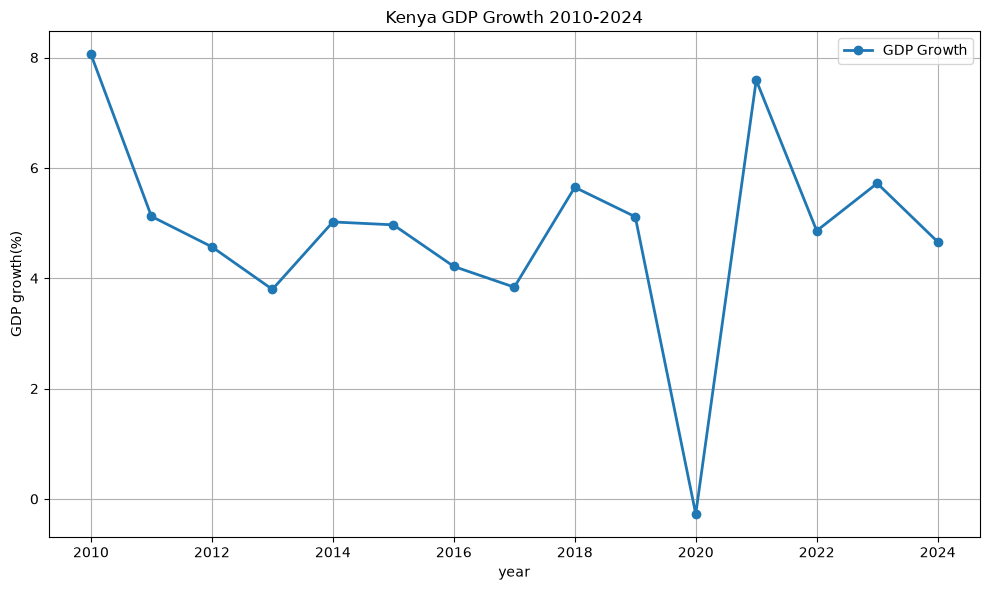

In [57]:
import matplotlib.pyplot as plt

years= summary_df['year'].values
gdp= summary_df['gdp'].values

fig,ax = plt.subplots(figsize=(10,6))
ax.plot(years,gdp,marker='o',linewidth=2,markersize=6,label = 'GDP Growth')
ax.set_xlabel('year')
ax.set_ylabel('GDP growth(%)')
ax.set_title('Kenya GDP Growth 2010-2024')
ax.grid(True,alpha=1.0)
ax.legend()
plt.tight_layout()
plt.show()

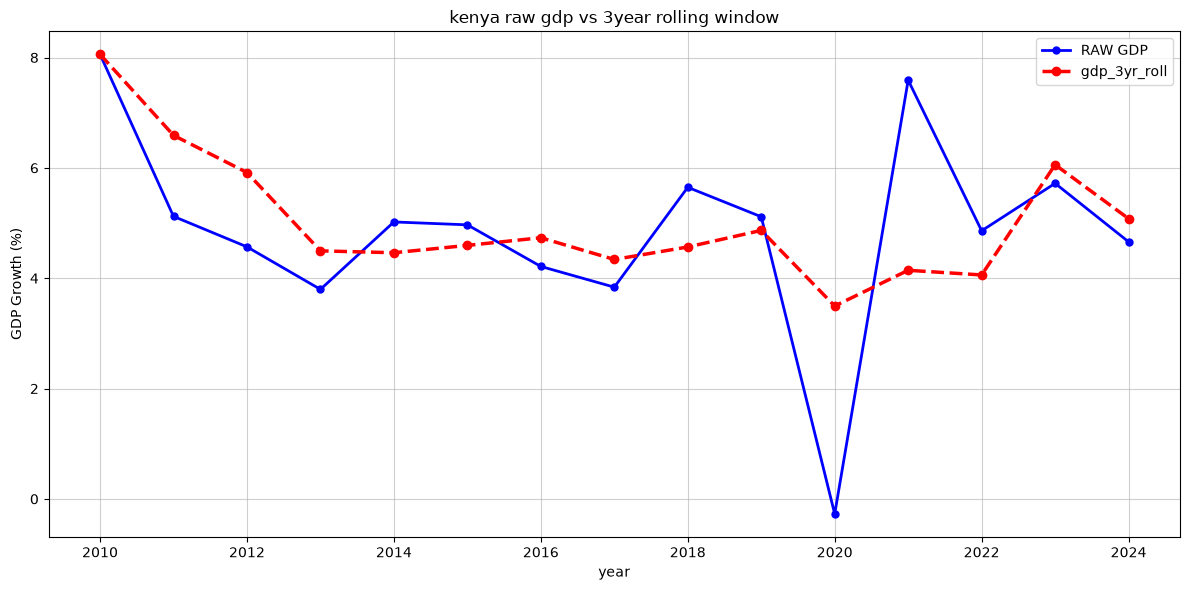

In [58]:
import matplotlib.pyplot as plt
years =summary_df['year'].values
gdp= summary_df['gdp'].values

gdp_series = summary_df.set_index('year')['gdp']
gdp_3yr_roll = gdp_series.rolling(window=3,min_periods=1).mean().values

fig,ax = plt.subplots(figsize=(12,6))
ax.plot(years,gdp,marker='o',linewidth=2,markersize=5,label ='RAW GDP',color='blue')
ax.plot(years,gdp_3yr_roll,marker='o',linewidth=2.5,label='gdp_3yr_roll',color='red',linestyle='--')

ax.set_title('kenya raw gdp vs 3year rolling window')
ax.set_xlabel('year')
ax.set_ylabel('GDP Growth (%)')
ax.grid(True,alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

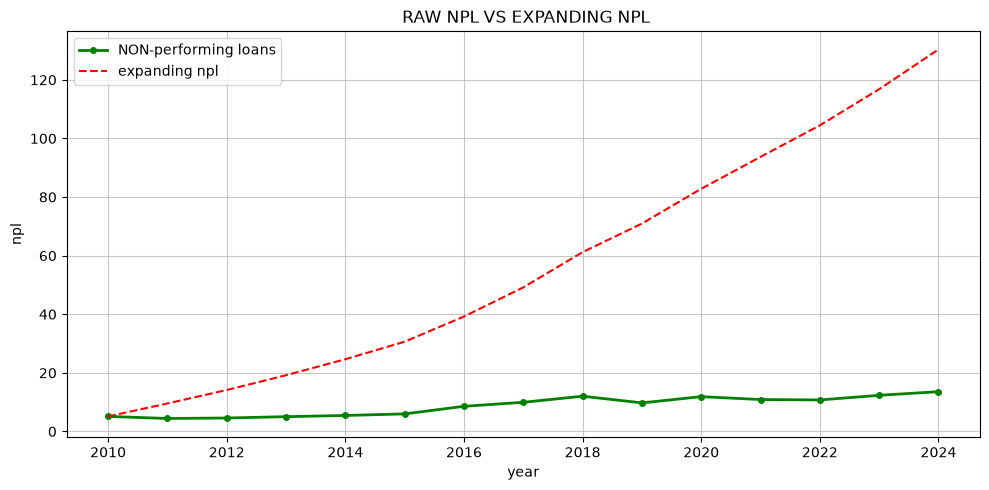

In [59]:
import matplotlib.pyplot as plt 

year = summary_df['year'].values
npl = summary_df['npl'].values

npl_series = summary_df.set_index('year')['npl']
exp_4npl = npl_series.expanding().sum().values

fig,ax = plt.subplots(figsize = (10,5))
ax.plot(year,npl,marker='o',linewidth=2,markersize=4,label='NON-performing loans',color='green')
ax.plot(year,exp_4npl,linewidth=1.5,label='expanding npl',color='red',linestyle='--')

ax.set_title(' RAW NPL VS EXPANDING NPL')
ax.set_xlabel('year')
ax.set_ylabel('npl')
ax.grid(True,alpha=0.7)
ax.legend()
plt.tight_layout()
plt.show()

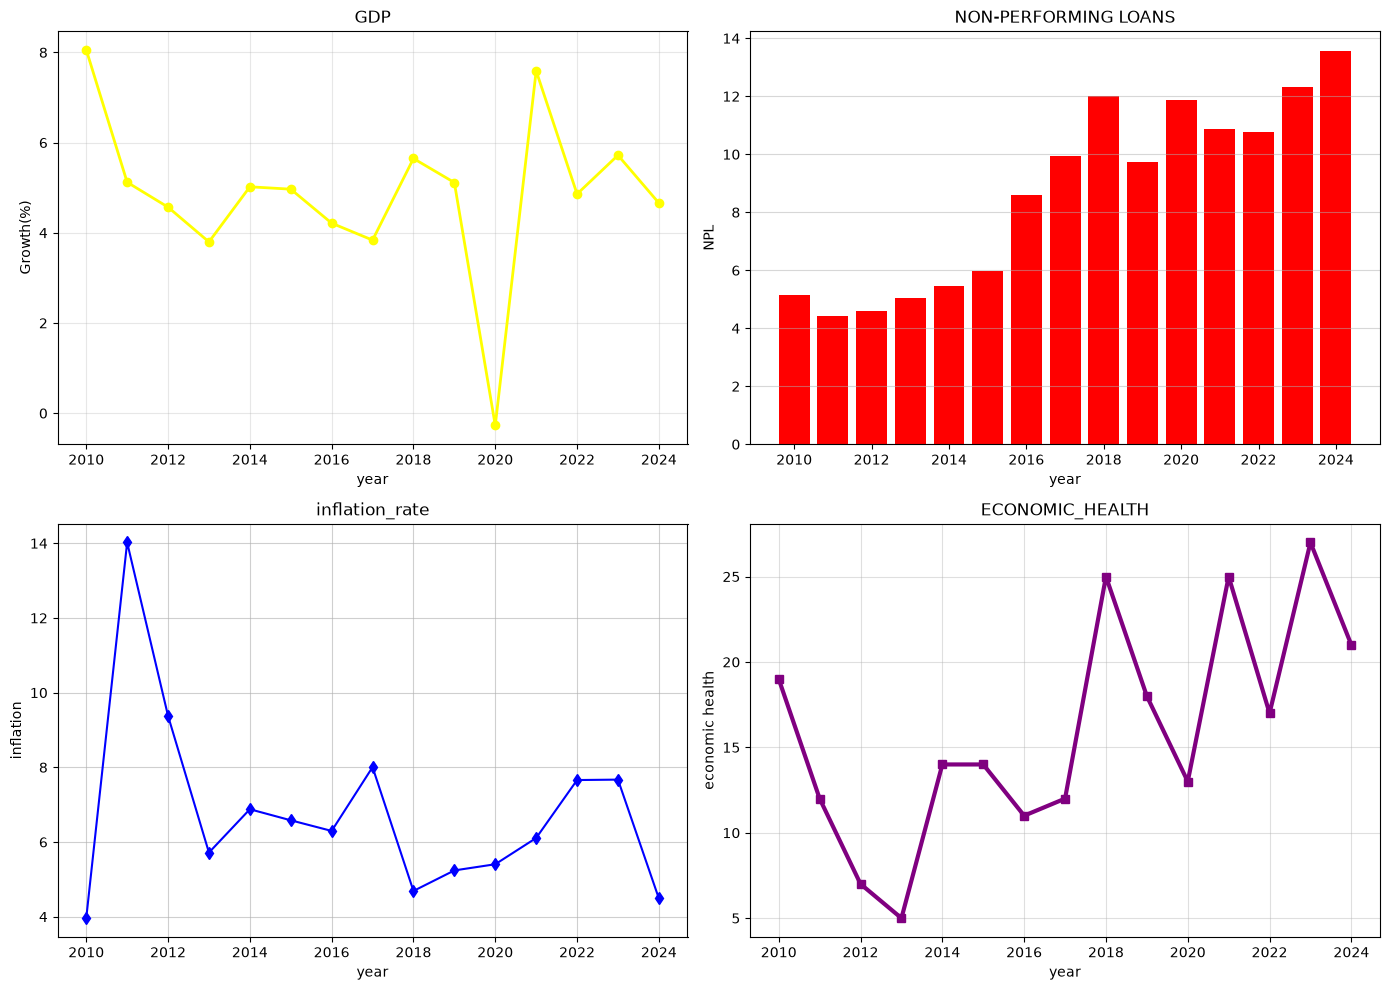

In [63]:
import matplotlib.pyplot as plt
year =summary_df['year'].values
gdp= summary_df['gdp'].values
npl=summary_df['npl'].values
inflation = summary_df['inflation'].values

gdp_series= summary_df.set_index('year')['gdp']
npl_series = summary_df.set_index('year')['npl']

fig,axes = plt.subplots(2,2,figsize=(14,10))
axes[0,0].plot(year,gdp,marker ='o',linewidth = 2,color='yellow')
axes[0,0].set_title('GDP')
axes[0,0].set_ylabel('Growth(%)')
axes[0,0].grid(True,alpha = 0.3)

axes[0,1].bar(year,npl,color='red',alpha=1.0)
axes[0,1].set_title('NON-PERFORMING LOANS')
axes[0,1].set_ylabel('NPL')
axes[0,1].grid(True,alpha=0.5,axis='y')

axes[1,0].plot(year,inflation,marker='d',linewidth=1.5,color='blue')
axes[1,0].set_title('inflation_rate')
axes[1,0].set_ylabel('inflation')
axes[1,0].grid(True,alpha=0.6)

gdp_rank = gdp_series.rank(ascending=True)
npl_rank= npl_series.rank(ascending=False)
economic_health = gdp_rank + (16-npl_rank).values

axes[1,1].plot(year,economic_health,marker='s',linewidth=3,color='purple',linestyle='-')
axes[1,1].set_title('ECONOMIC_HEALTH')
axes[1,1].set_ylabel('economic health')
axes[1,1].grid(True,alpha=0.4)

for ax in axes.flat:
    ax.set_xlabel('year')
plt.tight_layout()
plt.show()